In [7]:
import os
import sys
base_path = os.path.abspath(os.path.join(os.path.abspath("__file__"), '../../../../..'))
sys.path.append(base_path)

import pickle
from utils.utils import split_rawdata
import numpy as np

data_base_path = f'/data3/xxx/toy-gato'

In [8]:
def load_raw_data(num_nodes:int, check_data_num:dict):
    datasets = {}
    print('-'*80)
    for data_type in check_data_num.keys():
        path = f'{data_base_path}/data/used/_raw/cvrp/saved/cvrp{num_nodes}_{data_type}.pkl' 
        with open(path, 'rb') as f:
            dataset = pickle.load(f)
            check_num = check_data_num[data_type]
            if check_num != 0:
                dataset = split_rawdata(dataset, 0, check_num)
        datasets[data_type] = dataset
        assert len(dataset.answer_list) == len(dataset.problem_list) == len(dataset.cost_list)
        print(f'\t{data_type} dataset:   \t[{len(dataset.answer_list)}] raw data with [{len(dataset.seed_list)}] different random seeds, ave cost = [{np.mean(dataset.cost_list):.3f}]')    
    print('-'*80)
    return datasets

num_nodes = 50
check_data_num = {
    'problem': 0,
    'prompt': 0,
    'train': 0,
}

datasets = load_raw_data(num_nodes, check_data_num)

--------------------------------------------------------------------------------
	problem dataset:   	[15000] raw data with [750] different random seeds, ave cost = [10.372]
	prompt dataset:   	[5000] raw data with [250] different random seeds, ave cost = [10.355]
	train dataset:   	[201000] raw data with [10050] different random seeds, ave cost = [10.359]
--------------------------------------------------------------------------------


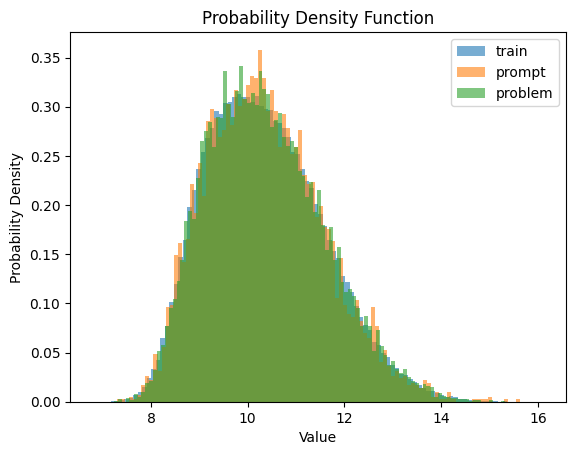

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# 绘制概率密度函数
plt.hist(datasets['train'].cost_list, bins=100, density=True, alpha=0.6, label='train') 
plt.hist(datasets['prompt'].cost_list, bins=100, density=True, alpha=0.6, label='prompt') 
plt.hist(datasets['problem'].cost_list, bins=100, density=True, alpha=0.6, label='problem') 
plt.title('Probability Density Function')
plt.xlabel('Value')
plt.ylabel('Probability Density')
plt.legend()
plt.show()

In [4]:
max(datasets['train'].cost_list)

10.668457224539022